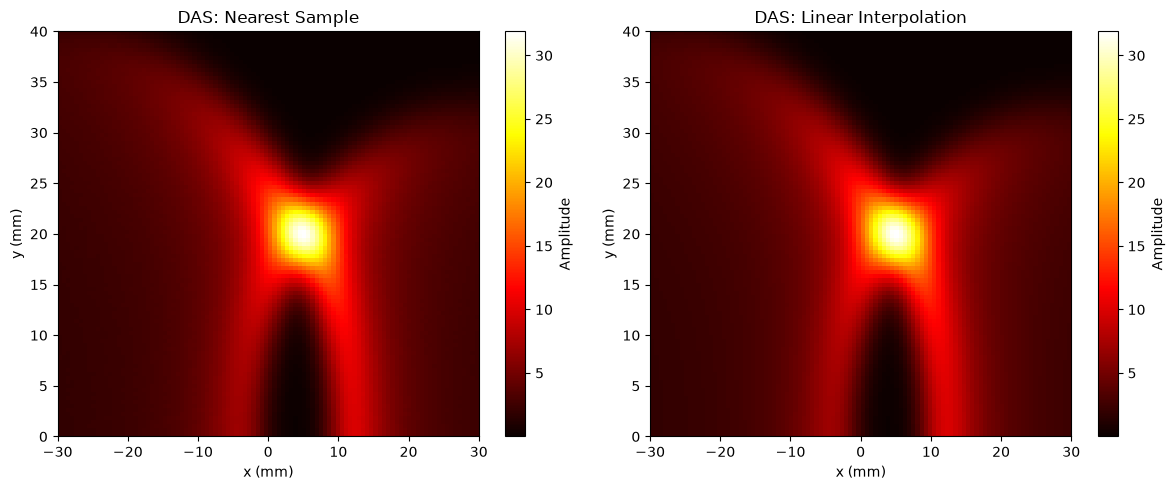

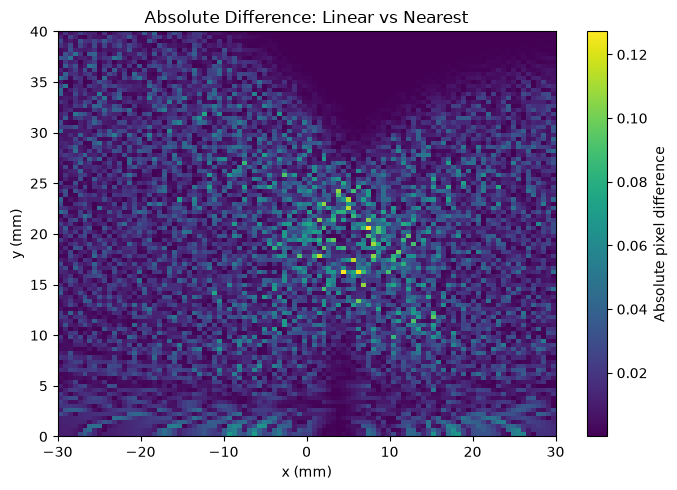

{
    "day": 26,
    "num_sensors": 32,
    "image_shape": [
        100,
        100
    ],
    "true_source_mm": [
        5.0,
        20.0
    ],
    "nearest_sample": {
        "peak_intensity": 31.893867622002485,
        "estimated_x_mm": 5.15151515151515,
        "estimated_y_mm": 19.797979797979796,
        "localization_error_mm": 0.2525252525252526
    },
    "linear_interpolation": {
        "peak_intensity": 31.897689381836166,
        "estimated_x_mm": 5.15151515151515,
        "estimated_y_mm": 19.797979797979796,
        "localization_error_mm": 0.2525252525252526
    },
    "comparison": {
        "mean_absolute_pixel_difference": 0.016878559997920366,
        "maximum_absolute_pixel_difference": 0.12726940857400137,
        "pixel_difference_rmse": 0.0231020693905434
    }
}

Day 26 comparison completed!
Results saved to: ..\outputs


In [1]:

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Simulation parameters (same setup as Days 24-25)
c = 1500.0
fs = 10e6
num_sensors = 32

sensor_x = np.linspace(-0.03, 0.03, num_sensors)
sensor_y = np.zeros(num_sensors)

source_x = 0.005
source_y = 0.020

duration = 60e-6
time = np.arange(0, duration, 1 / fs)
dt = time[1] - time[0]

distances = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)
arrival_times = distances / c

signals = np.zeros((num_sensors, len(time)))
pulse_width = 1.5e-6

for i in range(num_sensors):
    signals[i] = np.exp(
        -0.5 * ((time - arrival_times[i]) / pulse_width)**2
    )

# 2. Image grid
image_size = 100
x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)
X, Y = np.meshgrid(x_grid, y_grid)

# 3. DAS using nearest-sample selection (Day 24)
image_nearest = np.zeros(X.shape, dtype=float)

for i in range(num_sensors):
    distance = np.sqrt(
        (X - sensor_x[i])**2 +
        (Y - sensor_y[i])**2
    )
    tof = distance / c

    indices = np.rint(tof / dt).astype(int)
    valid = (indices >= 0) & (indices < len(time))

    contribution = np.zeros(X.shape)
    contribution[valid] = signals[i, indices[valid]]
    image_nearest += contribution

# 4. DAS using linear interpolation (Day 25)
image_linear = np.zeros(X.shape, dtype=float)

for i in range(num_sensors):
    distance = np.sqrt(
        (X - sensor_x[i])**2 +
        (Y - sensor_y[i])**2
    )
    tof = distance / c

    contribution = np.interp(
        tof.ravel(),
        time,
        signals[i],
        left=0.0,
        right=0.0
    ).reshape(X.shape)

    image_linear += contribution

# 5. Pixel-wise difference
difference = image_linear - image_nearest
absolute_difference = np.abs(difference)

mae = float(np.mean(absolute_difference))
max_pixel_difference = float(np.max(absolute_difference))
rmse = float(np.sqrt(np.mean(difference**2)))

# 6. Peak location and localization error
def get_peak_metrics(image):
    row, col = np.unravel_index(np.argmax(image), image.shape)

    estimated_x = float(X[row, col])
    estimated_y = float(Y[row, col])

    error_mm = float(
        np.sqrt(
            (estimated_x - source_x)**2 +
            (estimated_y - source_y)**2
        ) * 1000
    )

    return {
        "peak_intensity": float(np.max(image)),
        "estimated_x_mm": estimated_x * 1000,
        "estimated_y_mm": estimated_y * 1000,
        "localization_error_mm": error_mm
    }

nearest_metrics = get_peak_metrics(image_nearest)
linear_metrics = get_peak_metrics(image_linear)

# 7. Plot both reconstructions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(
    image_nearest,
    extent=[x_grid[0]*1000, x_grid[-1]*1000,
            y_grid[0]*1000, y_grid[-1]*1000],
    origin="lower",
    aspect="auto",
    cmap="hot"
)
axes[0].set_title("DAS: Nearest Sample")
axes[0].set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
fig.colorbar(im1, ax=axes[0], label="Amplitude")

im2 = axes[1].imshow(
    image_linear,
    extent=[x_grid[0]*1000, x_grid[-1]*1000,
            y_grid[0]*1000, y_grid[-1]*1000],
    origin="lower",
    aspect="auto",
    cmap="hot"
)
axes[1].set_title("DAS: Linear Interpolation")
axes[1].set_xlabel("x (mm)")
axes[1].set_ylabel("y (mm)")
fig.colorbar(im2, ax=axes[1], label="Amplitude")

plt.tight_layout()
plt.savefig(
    output_dir / "day26_das_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Plot absolute pixel differences
plt.figure(figsize=(7, 5))
plt.imshow(
    absolute_difference,
    extent=[x_grid[0]*1000, x_grid[-1]*1000,
            y_grid[0]*1000, y_grid[-1]*1000],
    origin="lower",
    aspect="auto",
    cmap="viridis"
)
plt.colorbar(label="Absolute pixel difference")
plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.title("Absolute Difference: Linear vs Nearest")
plt.tight_layout()
plt.savefig(
    output_dir / "day26_das_pixel_difference.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 9. Save numerical results
results = {
    "day": 26,
    "num_sensors": num_sensors,
    "image_shape": list(image_nearest.shape),
    "true_source_mm": [
        source_x * 1000,
        source_y * 1000
    ],
    "nearest_sample": nearest_metrics,
    "linear_interpolation": linear_metrics,
    "comparison": {
        "mean_absolute_pixel_difference": mae,
        "maximum_absolute_pixel_difference": max_pixel_difference,
        "pixel_difference_rmse": rmse
    }
}

with open(
    output_dir / "day26_das_comparison_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nDay 26 comparison completed!")
print(f"Results saved to: {output_dir}")
